In [ ]:

# 資料處理與視覺化套件
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 資料集載入
from sklearn.datasets import load_iris, make_classification

# 資料前處理與交叉驗證
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV
)

# 分類演算法
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC, LinearSVC

# 分類評估指標
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# 其他工具
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 載入 Iris 資料集
iris = load_iris()

# 定義特徵與目標標籤
iris_X = iris.data
iris_y = iris.target

# 切分訓練集與測試集
iris_X_train, iris_X_test, iris_y_train, iris_y_test = train_test_split(
    iris_X,
    iris_y,
    test_size=0.2,
    random_state=42,
    stratify=iris_y
)

# 查看資料集大小
print("資料集特徵維度：", iris_X.shape)
print("目標標籤維度：", iris_y.shape)
print("訓練集維度：", iris_X_train.shape)
print("測試集維度：", iris_X_test.shape)

資料集特徵維度： (150, 4)
目標標籤維度： (150,)
訓練集維度： (120, 4)
測試集維度： (30, 4)


In [ ]:
# 建立三種分類模型
class_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

In [ ]:
from sklearn.model_selection import (
    StratifiedKFold,
    RepeatedStratifiedKFold,
    StratifiedShuffleSplit
)

# 分層 5 折交叉驗證
cv_stratified = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 重複分層 5 折交叉驗證
cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

# 分層隨機切分交叉驗證
cv_shuffle = StratifiedShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

# 整理三種交叉驗證方法
classification_cv_methods = {
    "StratifiedKFold": cv_stratified,
    "RepeatedStratifiedKFold": cv_repeated,
    "StratifiedShuffleSplit": cv_shuffle
}

In [ ]:
# 分類評估指標
classification_scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision_weighted",
    "Recall": "recall_weighted",
    "F1-score": "f1_weighted"
}

In [ ]:
# 儲存所有實驗結果
classification_results = []

# 三種交叉驗證 × 三種分類模型
for cv_name, cv_method in classification_cv_methods.items():

    for model_name, model in class_models.items():

        # 執行交叉驗證
        scores = cross_validate(
            model,
            iris_X_train,
            iris_y_train,
            cv=cv_method,
            scoring=classification_scoring
        )

        # 計算各項評估指標的平均值
        result = {
            "Cross Validation": cv_name,
            "Model": model_name,
            "Accuracy": scores["test_Accuracy"].mean(),
            "Precision": scores["test_Precision"].mean(),
            "Recall": scores["test_Recall"].mean(),
            "F1-score": scores["test_F1-score"].mean()
        }

        classification_results.append(result)

# 整理實驗結果
classification_results_df = pd.DataFrame(classification_results)

print("=== 分類模型交叉驗證結果 ===")
print(classification_results_df.round(4).to_string(index=False))


=== 分類模型交叉驗證結果 ===
       Cross Validation               Model  Accuracy  Precision  Recall  F1-score
        StratifiedKFold Logistic Regression    0.9583     0.9644  0.9583    0.9580
        StratifiedKFold       Decision Tree    0.9500     0.9570  0.9500    0.9496
        StratifiedKFold                 SVC    0.9667     0.9704  0.9667    0.9665
RepeatedStratifiedKFold Logistic Regression    0.9583     0.9649  0.9583    0.9579
RepeatedStratifiedKFold       Decision Tree    0.9500     0.9592  0.9500    0.9491
RepeatedStratifiedKFold                 SVC    0.9667     0.9714  0.9667    0.9664
 StratifiedShuffleSplit Logistic Regression    0.9667     0.9704  0.9667    0.9665
 StratifiedShuffleSplit       Decision Tree    0.9333     0.9352  0.9333    0.9333
 StratifiedShuffleSplit                 SVC    0.9583     0.9611  0.9583    0.9582


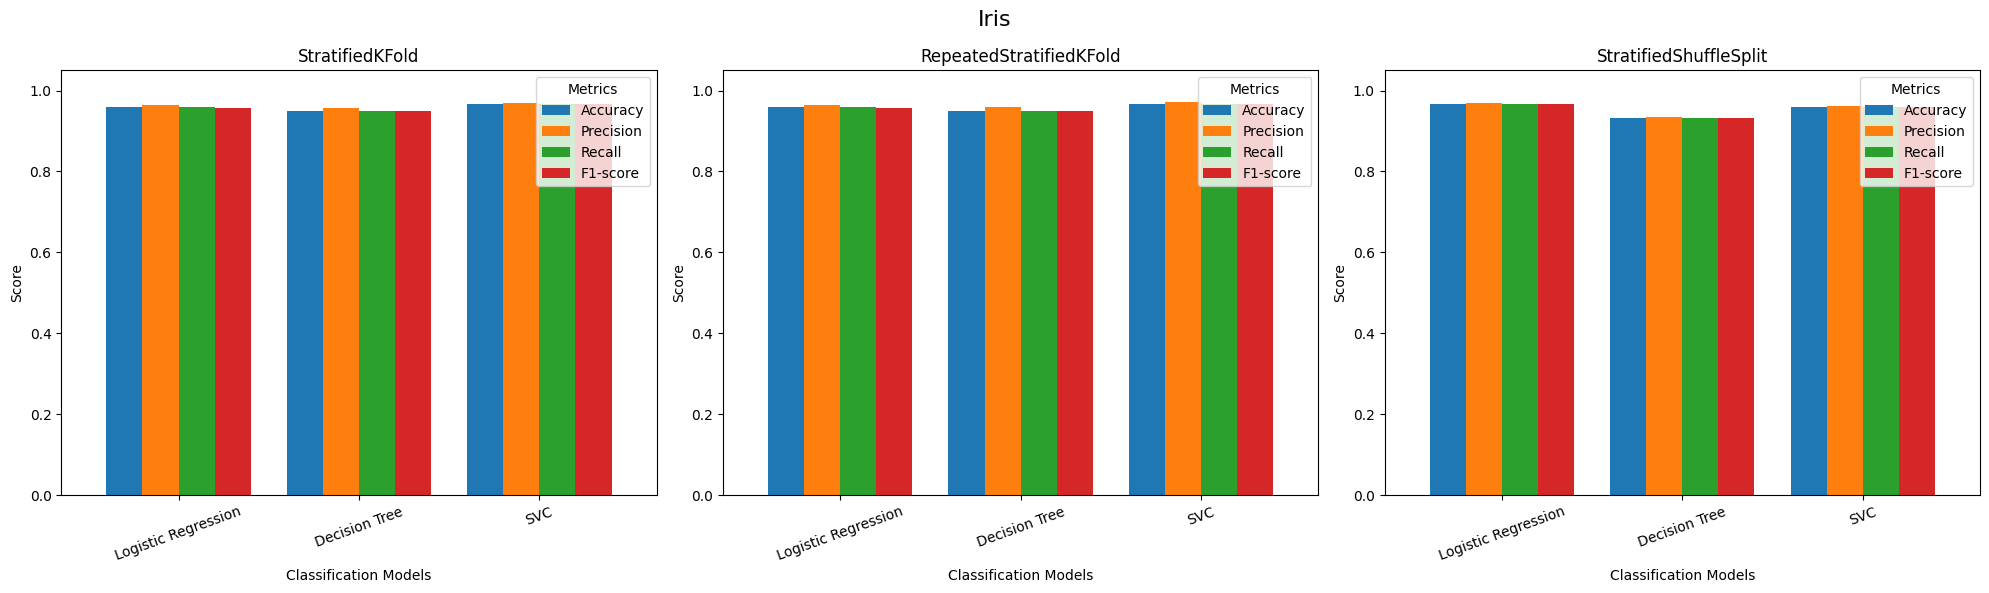

In [ ]:
# 設定評估指標
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

# 建立三張比較圖
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, cv_name in zip(axes, classification_cv_methods.keys()):

    # 取得目前交叉驗證方法的結果
    data = classification_results_df[
        classification_results_df["Cross Validation"] == cv_name
    ]

    # 整理模型與評估指標
    plot_data = data.set_index("Model")[metrics]

    # 繪製長條圖
    plot_data.plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    ax.set_title(cv_name)
    ax.set_xlabel("Classification Models")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Metrics")

plt.suptitle("Iris", fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:

# 比較各交叉驗證方法中，哪個模型的指標最高
for cv_name in classification_cv_methods.keys():

    data = classification_results_df[
        classification_results_df["Cross Validation"] == cv_name
    ]

    print(f"\n=== {cv_name} 最佳模型比較 ===")

    for metric in metrics:
        best_index = data[metric].idxmax()
        best_model = data.loc[best_index, "Model"]
        best_score = data.loc[best_index, metric]

        print(f"{metric}：{best_model} ({best_score:.4f})")


=== StratifiedKFold 最佳模型比較 ===
Accuracy：SVC (0.9667)
Precision：SVC (0.9704)
Recall：SVC (0.9667)
F1-score：SVC (0.9665)

=== RepeatedStratifiedKFold 最佳模型比較 ===
Accuracy：SVC (0.9667)
Precision：SVC (0.9714)
Recall：SVC (0.9667)
F1-score：SVC (0.9664)

=== StratifiedShuffleSplit 最佳模型比較 ===
Accuracy：Logistic Regression (0.9667)
Precision：Logistic Regression (0.9704)
Recall：Logistic Regression (0.9667)
F1-score：Logistic Regression (0.9665)


In [ ]:
# 三種分類模型的超參數搜尋範圍
class_param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10, 100]
    },

    "Decision Tree": {
        "model__max_depth": [None, 3, 5, 10],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4]
    },

    "SVC": {
        "model__C": [0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"],
        "model__gamma": ["scale", "auto"]
    }
}

# 儲存調校後的模型與結果
class_tuned_models = {}
class_tuning_results = []

# 逐一進行超參數調校
for name, model in class_models.items():

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=class_param_grids[name],
        scoring="f1_weighted",
        cv=cv_stratified,
        n_jobs=-1
    )

    # 使用訓練資料進行參數搜尋
    grid_search.fit(iris_X_train, iris_y_train)

    # 儲存最佳模型
    class_tuned_models[name] = grid_search.best_estimator_

    # 儲存調校結果
    class_tuning_results.append({
        "Model": name,
        "Best Parameters": grid_search.best_params_,
        "Best CV F1-score": grid_search.best_score_
    })

# 整理結果
class_tuning_df = pd.DataFrame(class_tuning_results)

print("=== 分類模型超參數調校結果 ===")
print(class_tuning_df.to_string(index=False))


=== 分類模型超參數調校結果 ===
              Model                                                                         Best Parameters  Best CV F1-score
Logistic Regression                                                                        {'model__C': 10}          0.966337
      Decision Tree {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}          0.957971
                SVC                   {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}          0.974902


In [ ]:
# 建立人工分類資料集
make_X, make_y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=8,
    n_redundant=0,
    n_repeated=0,
    n_classes=3,
    n_clusters_per_class=2,
    random_state=42
)

# 切分訓練集與測試集
make_X_train, make_X_test, make_y_train, make_y_test = train_test_split(
    make_X,
    make_y,
    test_size=0.2,
    random_state=42,
    stratify=make_y
)

# 查看資料集資訊
print("=== make_classification 資料集資訊 ===")
print("資料筆數：", make_X.shape[0])
print("特徵數量：", make_X.shape[1])
print("分類類別數量：", len(np.unique(make_y)))

print("\n=== 資料切分結果 ===")
print("訓練集：", make_X_train.shape)
print("測試集：", make_X_test.shape)
print("訓練標籤：", make_y_train.shape)
print("測試標籤：", make_y_test.shape)


=== make_classification 資料集資訊 ===
資料筆數： 1000
特徵數量： 10
分類類別數量： 3

=== 資料切分結果 ===
訓練集： (800, 10)
測試集： (200, 10)
訓練標籤： (800,)
測試標籤： (200,)


In [ ]:
# 分層 5 折交叉驗證
make_cv_stratified = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 重複分層 5 折交叉驗證
make_cv_repeated = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=42
)

# 分層隨機切分交叉驗證
make_cv_shuffle = StratifiedShuffleSplit(
    n_splits=5,
    test_size=0.2,
    random_state=42
)

# 整理三種交叉驗證方法
make_classification_cv_methods = {
    "StratifiedKFold": make_cv_stratified,
    "RepeatedStratifiedKFold": make_cv_repeated,
    "StratifiedShuffleSplit": make_cv_shuffle
}

In [ ]:
# 儲存 make_classification 實驗結果
make_classification_results = []

# 三種交叉驗證 × 三種分類模型
for cv_name, cv_method in make_classification_cv_methods.items():

    for model_name, model in class_models.items():

        scores = cross_validate(
            model,
            make_X_train,
            make_y_train,
            cv=cv_method,
            scoring=classification_scoring
        )

        # 計算各項指標平均值
        result = {
            "Cross Validation": cv_name,
            "Model": model_name,
            "Accuracy": scores["test_Accuracy"].mean(),
            "Precision": scores["test_Precision"].mean(),
            "Recall": scores["test_Recall"].mean(),
            "F1-score": scores["test_F1-score"].mean()
        }

        make_classification_results.append(result)

# 整理實驗結果
make_classification_results_df = pd.DataFrame(
    make_classification_results
)

print("=== make_classification 交叉驗證結果 ===")
print(make_classification_results_df.round(4).to_string(index=False))


=== make_classification 交叉驗證結果 ===
       Cross Validation               Model  Accuracy  Precision  Recall  F1-score
        StratifiedKFold Logistic Regression    0.7175     0.7198  0.7175    0.7163
        StratifiedKFold       Decision Tree    0.7175     0.7202  0.7175    0.7174
        StratifiedKFold                 SVC    0.8738     0.8770  0.8738    0.8732
RepeatedStratifiedKFold Logistic Regression    0.7229     0.7255  0.7229    0.7223
RepeatedStratifiedKFold       Decision Tree    0.7283     0.7301  0.7283    0.7279
RepeatedStratifiedKFold                 SVC    0.8792     0.8827  0.8792    0.8788
 StratifiedShuffleSplit Logistic Regression    0.6975     0.6993  0.6975    0.6967
 StratifiedShuffleSplit       Decision Tree    0.7238     0.7253  0.7238    0.7228
 StratifiedShuffleSplit                 SVC    0.8788     0.8798  0.8788    0.8785


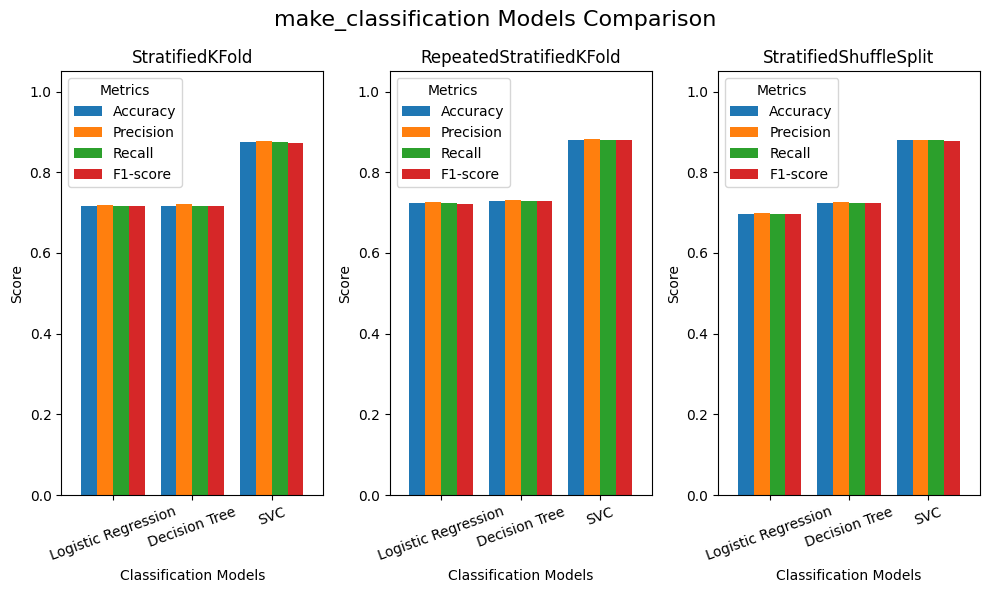

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

fig, axes = plt.subplots(1, 3, figsize=(10, 6))

for ax, cv_name in zip(
    axes,
    make_classification_cv_methods.keys()
):

    # 取得目前交叉驗證方法的結果
    data = make_classification_results_df[
        make_classification_results_df["Cross Validation"] == cv_name
    ]

    plot_data = data.set_index("Model")[metrics]

    # 繪製長條圖
    plot_data.plot(
        kind="bar",
        ax=ax,
        width=0.8
    )

    ax.set_title(cv_name)
    ax.set_xlabel("Classification Models")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Metrics")

plt.suptitle(
    "make_classification Models Comparison",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
for cv_name in make_classification_cv_methods.keys():

    data = make_classification_results_df[
        make_classification_results_df["Cross Validation"] == cv_name
    ]

    print(f"\n=== {cv_name} 最佳模型 ===")

    for metric in metrics:

        best_index = data[metric].idxmax()
        best_model = data.loc[best_index, "Model"]
        best_score = data.loc[best_index, metric]

        print(f"{metric}：{best_model} ({best_score:.4f})")



=== StratifiedKFold 最佳模型 ===
Accuracy：SVC (0.8737)
Precision：SVC (0.8770)
Recall：SVC (0.8737)
F1-score：SVC (0.8732)

=== RepeatedStratifiedKFold 最佳模型 ===
Accuracy：SVC (0.8792)
Precision：SVC (0.8827)
Recall：SVC (0.8792)
F1-score：SVC (0.8788)

=== StratifiedShuffleSplit 最佳模型 ===
Accuracy：SVC (0.8787)
Precision：SVC (0.8798)
Recall：SVC (0.8787)
F1-score：SVC (0.8785)


In [ ]:
# 儲存 make_classification 調校後的模型與結果
make_classification_tuned_models = {}
make_classification_tuning_results = []

# 逐一調校三種分類模型
for name, model in class_models.items():

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=class_param_grids[name],
        scoring="f1_weighted",
        cv=make_cv_stratified,
        n_jobs=-1
    )

    # 使用 make_classification 訓練資料進行調校
    grid_search.fit(make_X_train, make_y_train)

    # 儲存最佳模型
    make_classification_tuned_models[name] = grid_search.best_estimator_

    # 儲存調校結果
    make_classification_tuning_results.append({
        "Model": name,
        "Best Parameters": grid_search.best_params_,
        "Best CV F1-score": grid_search.best_score_
    })

# 整理調校結果
make_classification_tuning_df = pd.DataFrame(
    make_classification_tuning_results
)
print("=== make_classification 超參數調校結果 ===")
print(make_classification_tuning_df.to_string(index=False))


=== make_classification 超參數調校結果 ===
              Model                                                                       Best Parameters  Best CV F1-score
Logistic Regression                                                                       {'model__C': 1}          0.716329
      Decision Tree {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}          0.733584
                SVC                      {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}          0.873164
